# Lab 3.8 — Can our decoder reproduce GPT-2 small?

Load the published GPT-2 small weights into the Lab 3.7 architecture. Compare the same prompt against the Hugging Face implementation at each block boundary in float32 on CPU.

## Map the checkpoint

GPT-2 stores its projection matrices in input-by-output order. PyTorch Linear expects output-by-input order. Even the square attention output matrix needs transposing. LayerNorm scales and embedding tables already match. The reference loader below uses the original layout.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from llm_lab.experiments import record, show

torch.manual_seed(34)
torch.set_num_threads(1)

from tokenizers import Tokenizer
from safetensors.torch import load_file
from transformers import GPT2Config, GPT2LMHeadModel
from llm_lab.gpt import GPT
from llm_lab.assets import asset
weights = load_file(str(asset("model.safetensors")))
tokenizer = Tokenizer.from_file(str(asset("tokenizer.json")))
reference = GPT2LMHeadModel(GPT2Config(attn_implementation="eager")).eval()
ref_params = {k:weights[k] for k in reference.transformer.state_dict()}
reference.transformer.load_state_dict(ref_params)
ours = GPT(50257,1024,768,12,12).eval()
mapped = {}
for name in ours.state_dict():
    tensor = weights[name]
    if name.endswith(("c_attn.weight","c_proj.weight","c_fc.weight")):
        tensor = tensor.T
    mapped[name] = tensor
ours.load_state_dict(mapped)
print("Unique model parameters:", sum(p.numel() for p in ours.parameters()))

Unique model parameters: 124439808


## Find the first disagreeing tensor

Record embeddings, every block output, the final normalization and every vocabulary logit. Compare raw tensors before sampling. A plausible continuation alone could hide a mapping error. Which boundary would first expose a transposed output projection?

Top next pieces: [' not', ' to', ' the', ' that', ' a']
Maximum absolute logit difference: 8.392333984375e-05
Out[2]: PosixPath('checkpoints/lab38/parity.npz')


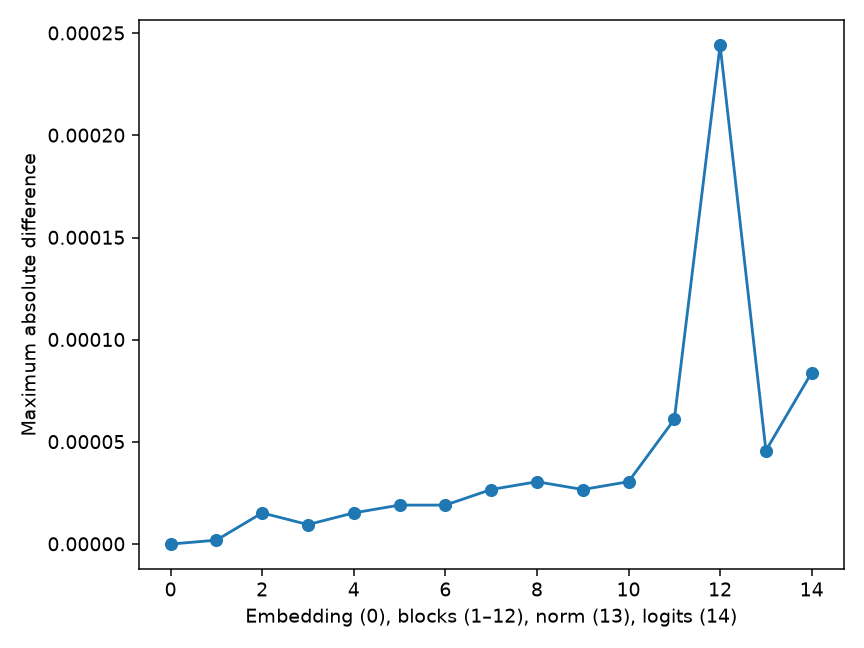

In [2]:
prompt = "The meaning of life is"
ids = torch.tensor([tokenizer.encode(prompt).ids])
def trace(model, blocks, final_norm, output):
    stages = []
    handles = [blocks[0].register_forward_pre_hook(lambda m, a: stages.append(a[0].detach()))]
    def capture(module, args, result):
        stages.append((result[0] if isinstance(result, tuple) else result).detach())
    handles += [layer.register_forward_hook(capture) for layer in [*blocks, final_norm]]
    try:
        with torch.no_grad():
            stages.append(output(model(ids)).detach())
    finally:
        for hook in handles:
            hook.remove()
    return stages
a = trace(ours, ours.h, ours.ln_f, lambda x:x)
b = trace(reference, reference.transformer.h, reference.transformer.ln_f, lambda x:x.logits)
assert len(a) == len(b) == 15
errors = []
for i,(x,y) in enumerate(zip(a,b)):
    errors.append((x-y).abs().max().item())
    torch.testing.assert_close(x,y,atol=0.002,rtol=1e-4,msg=lambda s: f"Boundary {i}: {s}")
top = a[-1][0,-1].topk(5).indices.tolist()
print("Top next pieces:", [tokenizer.decode([i]) for i in top])
print("Maximum absolute logit difference:", errors[-1])
plt.plot(range(15),errors,marker="o")
plt.xlabel("Embedding (0), blocks (1–12), norm (13), logits (14)")
plt.ylabel("Maximum absolute difference")
show(38,"parity")
record(38,"parity", ids=ids, top=top, max_errors=errors)

## Reading the result

The reference and our implementation share the original checkpoint and the prompt IDs. The comparison covers all prompt positions and vocabulary scores. To diagnose a failed match, inspect the first boundary with a discrepancy and trace the individual operations in that block. [Pinned GPT-2 small checkpoint](https://huggingface.co/openai-community/gpt2/tree/607a30d783dfa663caf39e06633721c8d4cfcd7e) · [Original GPT-2 model](https://github.com/openai/gpt-2/blob/master/src/model.py)